<a href="https://colab.research.google.com/github/IsmaeelDhikr/IsmaeelDhikr/blob/main/Copy_of_XiotBenchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from functools import partial
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.utils import _safe_indexing

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Xiot_featureBenchmark.csv to Xiot_featureBenchmark.csv
Saving Xiot_targBenchmark.csv to Xiot_targBenchmark.csv


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Xiot_DatasetBenchmark.csv to Xiot_DatasetBenchmark.csv


In [ ]:
map_classXiot = pd.read_csv("Xiot_DatasetBenchmark.csv")

featmap = map_classXiot.drop(columns = "class3")
targmap = map_classXiot.class3

map_classXiot.shape, featmap.shape, targmap.shape
#featmap = pd.read_csv("Xiot_featureBenchmark.csv")
#targmap = pd.read_csv("Xiot_targBenchmark.csv")



((505234, 62), (505234, 61), (505234,))

In [ ]:
# Inspect the actual classes
print("Unique target labels:", np.unique(targmap))

print("\nClass distribution:")
print(pd.Series(targmap).value_counts().sort_index())

Unique target labels: ['Attack' 'Normal']

Class distribution:
class3
Attack    183075
Normal    322159
Name: count, dtype: int64


In [ ]:
# Replace these illustrative entries with the dataset's actual labels.
class_mapping = {
    0: "Normal",
    1: "Attack",
    #2: "DoS",
    #3: "Reconnaissance"
}

In [ ]:
# Split the dataset
Xtrain, Xtest, ytrain, ytest = train_test_split(featmap, targmap, test_size=0.3, stratify=targmap, random_state=42)

classes = np.unique(ytrain)

# Ensure every class has a corresponding display name.
class_names = [class_mapping.get(label, str(label))
    for label in classes
]

print("Training samples:", len(ytrain))
print("Testing samples:", len(ytest))
print("Number of features:", Xtrain.shape[1])

print("\nClass labels:")
for label, name in zip(classes, class_names):
    print(f"{label} = {name}")

Training samples: 353663
Testing samples: 151571
Number of features: 61

Class labels:
Attack = Attack
Normal = Normal


In [ ]:
# Define Classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        #class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        #n_estimators=200,
        #class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        #C=1.0,
        #probability=True,
        #class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        #n_neighbors=5,
        #weights="distance",
        n_jobs=-1
    ),

    "MLP": MLPClassifier(
        max_iter=1000,
        random_state=42
    ),
    "Naive Bayes": GaussianNB()
}

In [ ]:
# Configure leakage-safe pipelines
from sklearn.preprocessing import StandardScaler

n_features = Xtrain.shape[1]

def build_pipeline(classifier):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", clone(classifier))
    ])

In [ ]:
# Five-fold cross-validation and evaluation
# Cross-validation configuration
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(Xtrain, ytrain))

y_train_array = np.asarray(ytrain)

# Store all experimental results
cv_results = []

# Store out-of-fold predictions and probabilities
oof_predictions = {}
oof_probabilities = {}

# Store fitted pipelines
fitted_models = {}

# Positive class for binary ROC-AUC
positive_label = classes[0] if len(classes) == 2 else None

for name, classifier in classifiers.items():

    print("\n" + "=" * 70)
    print(f"CLASSIFIER: {name}")
    print("=" * 70)

    pipeline = build_pipeline(classifier)

    # Out-of-fold storage
    oof_pred = np.empty(
        len(y_train_array),
        dtype=object
    )

    oof_prob = np.zeros(
        (len(y_train_array), len(classes))
    )

    fold_metrics = []

    # Five-fold evaluation
    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

        X_fold_train = _safe_indexing(Xtrain, train_idx)
        X_fold_val = _safe_indexing(Xtrain, val_idx)

        y_fold_train = y_train_array[train_idx]
        y_fold_val = y_train_array[val_idx]

        model = clone(pipeline)
        model.fit(X_fold_train, y_fold_train)

        # Predictions
        predictions = model.predict(X_fold_val)

        # Probability estimates
        if hasattr(model.named_steps["classifier"], "predict_proba"):
            probabilities = model.predict_proba(X_fold_val)
        else:
            # fallback for models like linear SVM without probability=True
            decision_function = model.decision_function(X_fold_val)
            # Convert 1D decision function to pseudo-probabilities for binary classification
            exp_dec = np.exp(decision_function)
            probabilities = np.vstack([1 / (1 + exp_dec), exp_dec / (1 + exp_dec)]).T

        # Align probabilities with global class order
        fold_classes = model.named_steps["classifier"].classes_

        aligned_prob = np.zeros((len(val_idx), len(classes)))

        for j, label in enumerate(fold_classes):
            global_index = np.where(classes == label)[0][0]
            aligned_prob[:, global_index] = probabilities[:, j]

        oof_pred[val_idx] = predictions
        oof_prob[val_idx] = aligned_prob

        # Fold evaluation
        fold_accuracy = accuracy_score(y_fold_val, predictions)

        fold_precision = precision_score(
            y_fold_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        fold_recall = recall_score(
            y_fold_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        fold_f1 = f1_score(
            y_fold_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        if len(classes) == 2:
            pos_idx = np.where(classes == positive_label)[0][0]
            fold_auc = roc_auc_score((y_fold_val == positive_label).astype(int), aligned_prob[:, pos_idx])
        else:
            fold_auc = roc_auc_score(
                y_fold_val,
                aligned_prob,
                labels=classes,
                multi_class="ovr",
                average="macro"
            )

        fold_metrics.append({
            "Fold": fold_number,
            "Accuracy": fold_accuracy,
            "Precision": fold_precision,
            "Recall": fold_recall,
            "F1": fold_f1,
            "ROC_AUC": fold_auc
        })

        print(
            f"Fold {fold_number}: "
            f"Accuracy={fold_accuracy:.4f}, "
            f"F1={fold_f1:.4f}, "
            f"AUC={fold_auc:.4f}"
        )

    # Store OOF outputs
    oof_predictions[name] = oof_pred
    oof_probabilities[name] = oof_prob

    fold_df = pd.DataFrame(fold_metrics)

    # Mean and standard deviation across folds
    cv_results.append({
        "Classifier": name,
        "Accuracy Mean": fold_df["Accuracy"].mean(),
        "Accuracy SD": fold_df["Accuracy"].std(ddof=1),
        "Precision Mean": fold_df["Precision"].mean(),
        "Precision SD": fold_df["Precision"].std(ddof=1),
        "Recall Mean": fold_df["Recall"].mean(),
        "Recall SD": fold_df["Recall"].std(ddof=1),
        "F1 Mean": fold_df["F1"].mean(),
        "F1 SD": fold_df["F1"].std(ddof=1),
        "ROC-AUC Mean": fold_df["ROC_AUC"].mean(),
        "ROC-AUC SD": fold_df["ROC_AUC"].std(ddof=1)
    })

    # Fit final pipeline on all development data
    final_pipeline = clone(pipeline)
    final_pipeline.fit(Xtrain, ytrain)
    fitted_models[name] = final_pipeline

print("\nSix-classifier cross-validation completed.")


CLASSIFIER: Logistic Regression
Fold 1: Accuracy=0.9762, F1=0.9740, AUC=0.9912
Fold 2: Accuracy=0.9756, F1=0.9734, AUC=0.9907
Fold 3: Accuracy=0.9747, F1=0.9723, AUC=0.9904
Fold 4: Accuracy=0.9759, F1=0.9737, AUC=0.9909
Fold 5: Accuracy=0.9752, F1=0.9729, AUC=0.9908

CLASSIFIER: Random Forest
Fold 1: Accuracy=0.9987, F1=0.9985, AUC=0.9999
Fold 2: Accuracy=0.9987, F1=0.9986, AUC=1.0000
Fold 3: Accuracy=0.9985, F1=0.9984, AUC=1.0000
Fold 4: Accuracy=0.9989, F1=0.9988, AUC=1.0000
Fold 5: Accuracy=0.9988, F1=0.9987, AUC=1.0000

CLASSIFIER: SVM
Fold 1: Accuracy=0.9810, F1=0.9793, AUC=0.9984
Fold 2: Accuracy=0.9808, F1=0.9790, AUC=0.9986
Fold 3: Accuracy=0.9806, F1=0.9788, AUC=0.9984
Fold 4: Accuracy=0.9808, F1=0.9790, AUC=0.9983
Fold 5: Accuracy=0.9808, F1=0.9790, AUC=0.9983

CLASSIFIER: KNN
Fold 1: Accuracy=0.9864, F1=0.9853, AUC=0.9972
Fold 2: Accuracy=0.9865, F1=0.9854, AUC=0.9966
Fold 3: Accuracy=0.9868, F1=0.9857, AUC=0.9970
Fold 4: Accuracy=0.9866, F1=0.9855, AUC=0.9968
Fold 5: Accur

In [ ]:
# Comparative Cross-Validation performance table

cv_summary = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION COMPARATIVE RESULTS")

display(cv_summary.round(4).sort_values("F1 Mean", ascending=False))


CROSS-VALIDATION COMPARATIVE RESULTS


,Classifier,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,...,Recall SD,F1 Mean,F1 SD,ROC-AUC Mean,ROC-AUC SD
1,Random Forest,0.9987,0.0001,0.9986,0.0001,...,0.0001,0.9986,0.0001,1.0000,0.0000
4,MLP,0.9920,0.0011,0.9910,0.0014,...,0.0011,0.9913,0.0011,0.9995,0.0001
3,KNN,0.9866,0.0001,0.9853,0.0002,...,0.0001,0.9855,0.0001,0.9969,0.0002
2,SVM,0.9808,0.0001,0.9851,0.0001,...,0.0002,0.9790,0.0002,0.9984,0.0001
0,Logistic Regression,0.9755,0.0006,0.9777,0.0006,...,0.0007,0.9733,0.0006,0.9908,0.0003
5,Naive Bayes,0.6871,0.0231,0.7624,0.0077,...,0.0169,0.6866,0.0233,0.9411,0.0029


In [ ]:
# Tabular presentation in mean ± standard deviation format
publication_table = pd.DataFrame()

publication_table["Classifier"] = cv_summary["Classifier"]

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]:

    publication_table[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            cv_summary[f"{metric} Mean"],
            cv_summary[f"{metric} SD"]
        )
    ]

display(publication_table.sort_values("F1", ascending=False))

,Classifier,Accuracy,Precision,Recall,F1,ROC-AUC
1,Random Forest,0.9987 ± 0.0001,0.9986 ± 0.0001,0.9986 ± 0.0001,0.9986 ± 0.0001,1.0000 ± 0.0000
4,MLP,0.9920 ± 0.0011,0.9910 ± 0.0014,0.9916 ± 0.0011,0.9913 ± 0.0011,0.9995 ± 0.0001
3,KNN,0.9866 ± 0.0001,0.9853 ± 0.0002,0.9857 ± 0.0001,0.9855 ± 0.0001,0.9969 ± 0.0002
2,SVM,0.9808 ± 0.0001,0.9851 ± 0.0001,0.9738 ± 0.0002,0.9790 ± 0.0002,0.9984 ± 0.0001
0,Logistic Regression,0.9755 ± 0.0006,0.9777 ± 0.0006,0.9693 ± 0.0007,0.9733 ± 0.0006,0.9908 ± 0.0003
5,Naive Bayes,0.6871 ± 0.0231,0.7624 ± 0.0077,0.7520 ± 0.0169,0.6866 ± 0.0233,0.9411 ± 0.0029


In [ ]:
# Separate Classification for each classifier
for name in classifiers:

    print("\n" + "=" * 75)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 75)

    print(
        classification_report(
            y_train_array,
            oof_predictions[name],
            labels=classes,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

      Attack     0.9851    0.9467    0.9655    128152
      Normal     0.9704    0.9919    0.9810    225511

    accuracy                         0.9755    353663
   macro avg     0.9777    0.9693    0.9733    353663
weighted avg     0.9757    0.9755    0.9754    353663


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

      Attack     0.9981    0.9983    0.9982    128152
      Normal     0.9991    0.9989    0.9990    225511

    accuracy                         0.9987    353663
   macro avg     0.9986    0.9986    0.9986    353663
weighted avg     0.9987    0.9987    0.9987    353663


CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

      Attack     0.9988    0.9482    0.9728    128152
      Normal     0.9714    0.9994    0.9852    225511

    accuracy                         0.9808    353663
   macro avg     0

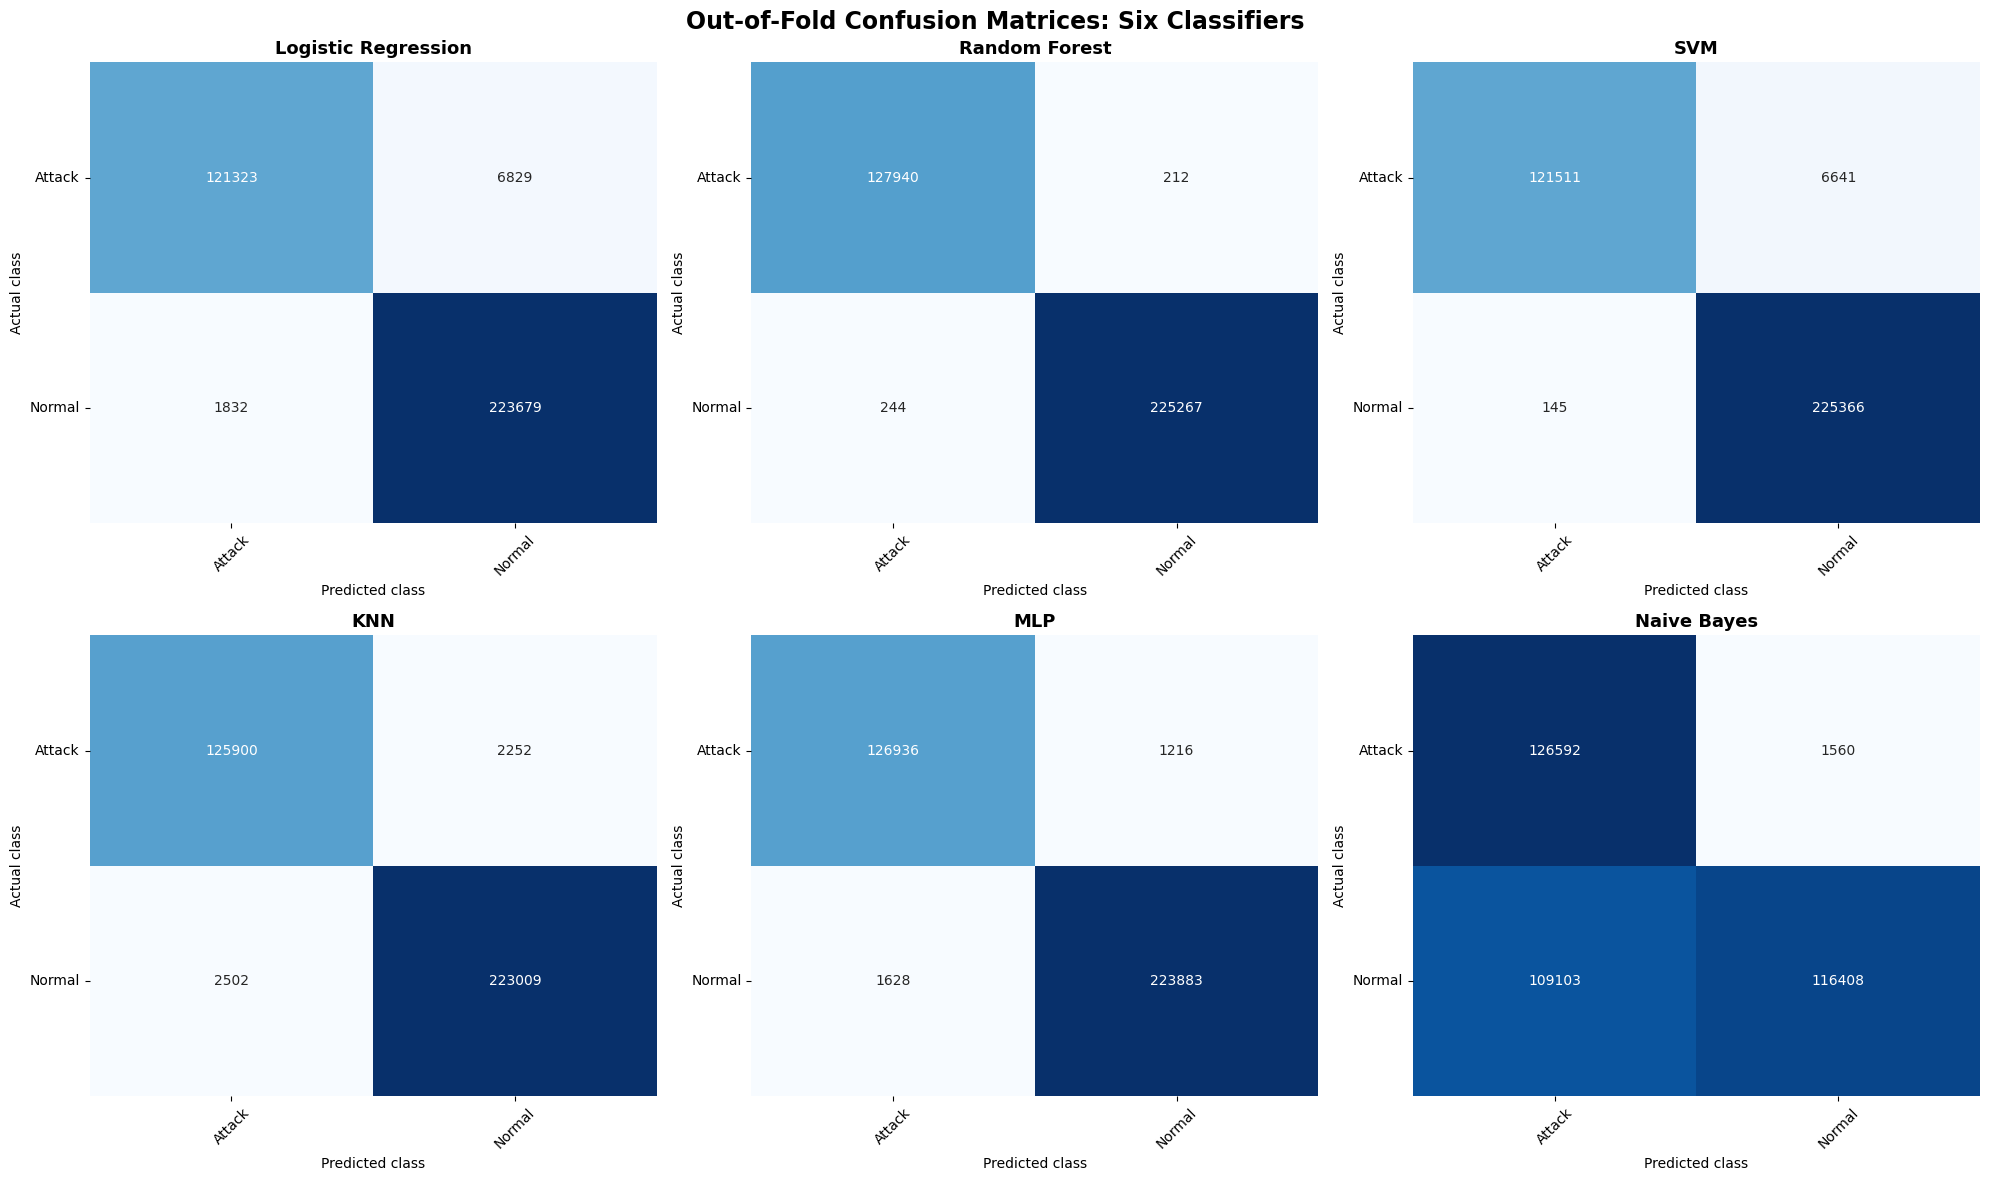

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

axes = axes.flatten()

for ax, name in zip(axes, classifiers):

    cm = confusion_matrix(y_train_array, oof_predictions[name], labels=classes)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        cbar=False
    )

    ax.set_title(name, fontsize=13, fontweight="bold")

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Out-of-Fold Confusion Matrices: Six Classifiers", fontsize=17, fontweight="bold")

plt.tight_layout()
plt.show()

In [ ]:
# Export each confusion matrix

for name in classifiers:

    cm = confusion_matrix(
        y_train_array,
        oof_predictions[name],
        labels=classes
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    print(f"\n{name} - Confusion Matrix")

    display(cm_df)


Logistic Regression - Confusion Matrix


,Attack,Normal
Attack,121323,6829
Normal,1832,223679



Random Forest - Confusion Matrix


,Attack,Normal
Attack,127940,212
Normal,244,225267



SVM - Confusion Matrix


,Attack,Normal
Attack,121511,6641
Normal,145,225366


... (2 outputs left out)


MLP - Confusion Matrix


,Attack,Normal
Attack,126936,1216
Normal,1628,223883



Naive Bayes - Confusion Matrix


,Attack,Normal
Attack,126592,1560
Normal,109103,116408


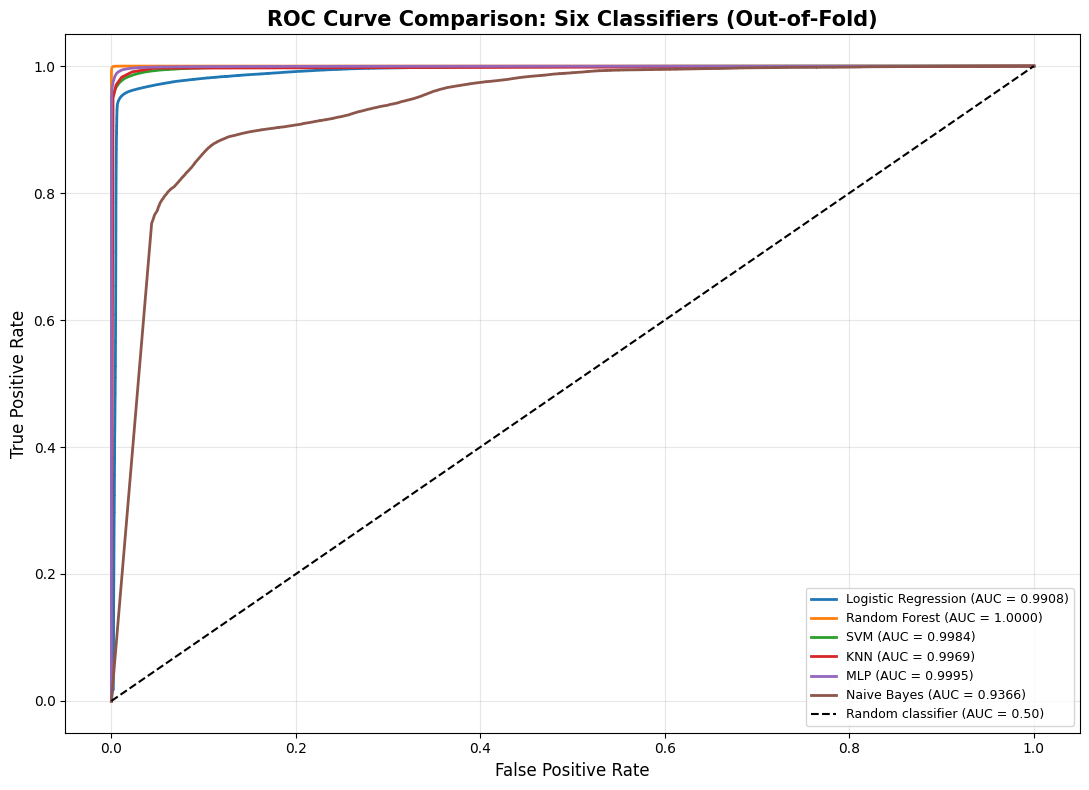

In [ ]:
# Binary ROC Curve
# The actual classes are strings: 'Attack' and 'Normal'
positive_label = 'Attack'

plt.figure(figsize=(11, 8))

for name in classifiers:

    probabilities = oof_probabilities[name]
    positive_index = np.where(classes == positive_label)[0][0]
    scores = probabilities[:, positive_index]
    y_binary = (y_train_array == positive_label).astype(int)

    fpr, tpr, _ = roc_curve(y_binary, scores)
    auc_score = roc_auc_score(y_binary, scores)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "ROC Curve Comparison: Six Classifiers (Out-of-Fold)",
    fontsize=15,
    fontweight="bold"
)

plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# NOW Independent test evaluation of all six classifiers
test_results = []

test_predictions = {}
test_probabilities = {}

for name, model in fitted_models.items():

    # Predict test observations
    predictions = model.predict(Xtest)

    # Dynamic probability estimates with fallback for models without predict_proba (like default SVC)
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(Xtest)
    elif hasattr(model, "decision_function"):
        decision_function = model.decision_function(Xtest)
        # Convert 1D decision function to pseudo-probabilities for binary classification
        exp_dec = np.exp(decision_function)
        probabilities = np.vstack([1 / (1 + exp_dec), exp_dec / (1 + exp_dec)]).T
    else:
        raise AttributeError(f"Model {name} has neither predict_proba nor decision_function.")

    test_predictions[name] = predictions
    test_probabilities[name] = probabilities

    # Metrics
    accuracy = accuracy_score(ytest, predictions)

    precision = precision_score(
        ytest,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        ytest,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        ytest,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    if len(classes) == 2:
        pos_idx = np.where(classes == positive_label)[0][0]
        auc_score = roc_auc_score((np.asarray(ytest) == positive_label).astype(int), probabilities[:, pos_idx])
    else:
        auc_score = roc_auc_score(
            ytest,
            probabilities,
            labels=classes,
            multi_class="ovr",
            average="macro"
        )

    test_results.append({
        "Classifier": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Macro ROC-AUC": auc_score
    })

    # Named classification report
    print("\n" + "=" * 75)
    print(f"INDEPENDENT TEST CLASSIFICATION REPORT: {name}")
    print("=" * 75)

    print(
        classification_report(
            ytest,
            predictions,
            labels=classes,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )


INDEPENDENT TEST CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

      Attack     0.9847    0.9449    0.9644     54923
      Normal     0.9694    0.9917    0.9804     96648

    accuracy                         0.9747    151571
   macro avg     0.9770    0.9683    0.9724    151571
weighted avg     0.9749    0.9747    0.9746    151571


INDEPENDENT TEST CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

      Attack     0.9984    0.9986    0.9985     54923
      Normal     0.9992    0.9991    0.9991     96648

    accuracy                         0.9989    151571
   macro avg     0.9988    0.9988    0.9988    151571
weighted avg     0.9989    0.9989    0.9989    151571


INDEPENDENT TEST CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

      Attack     0.9988    0.9465    0.9720     54923
      Normal     0.9705    0.9994    0.9847     96648

    accuracy         

In [ ]:
# Comparative Independent test results
test_summary = pd.DataFrame(test_results)

test_summary = test_summary.sort_values("Macro F1", ascending=False)

display(test_summary.round(4))

,Classifier,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
1,Random Forest,0.9989,0.9988,0.9988,0.9988,1.0000
4,MLP,0.9916,0.9921,0.9897,0.9909,0.9996
3,KNN,0.9880,0.9867,0.9874,0.9870,0.9972
2,SVM,0.9802,0.9847,0.9729,0.9783,0.9985
0,Logistic Regression,0.9747,0.9770,0.9683,0.9724,0.9904
5,Naive Bayes,0.6758,0.7590,0.7439,0.6753,0.9399


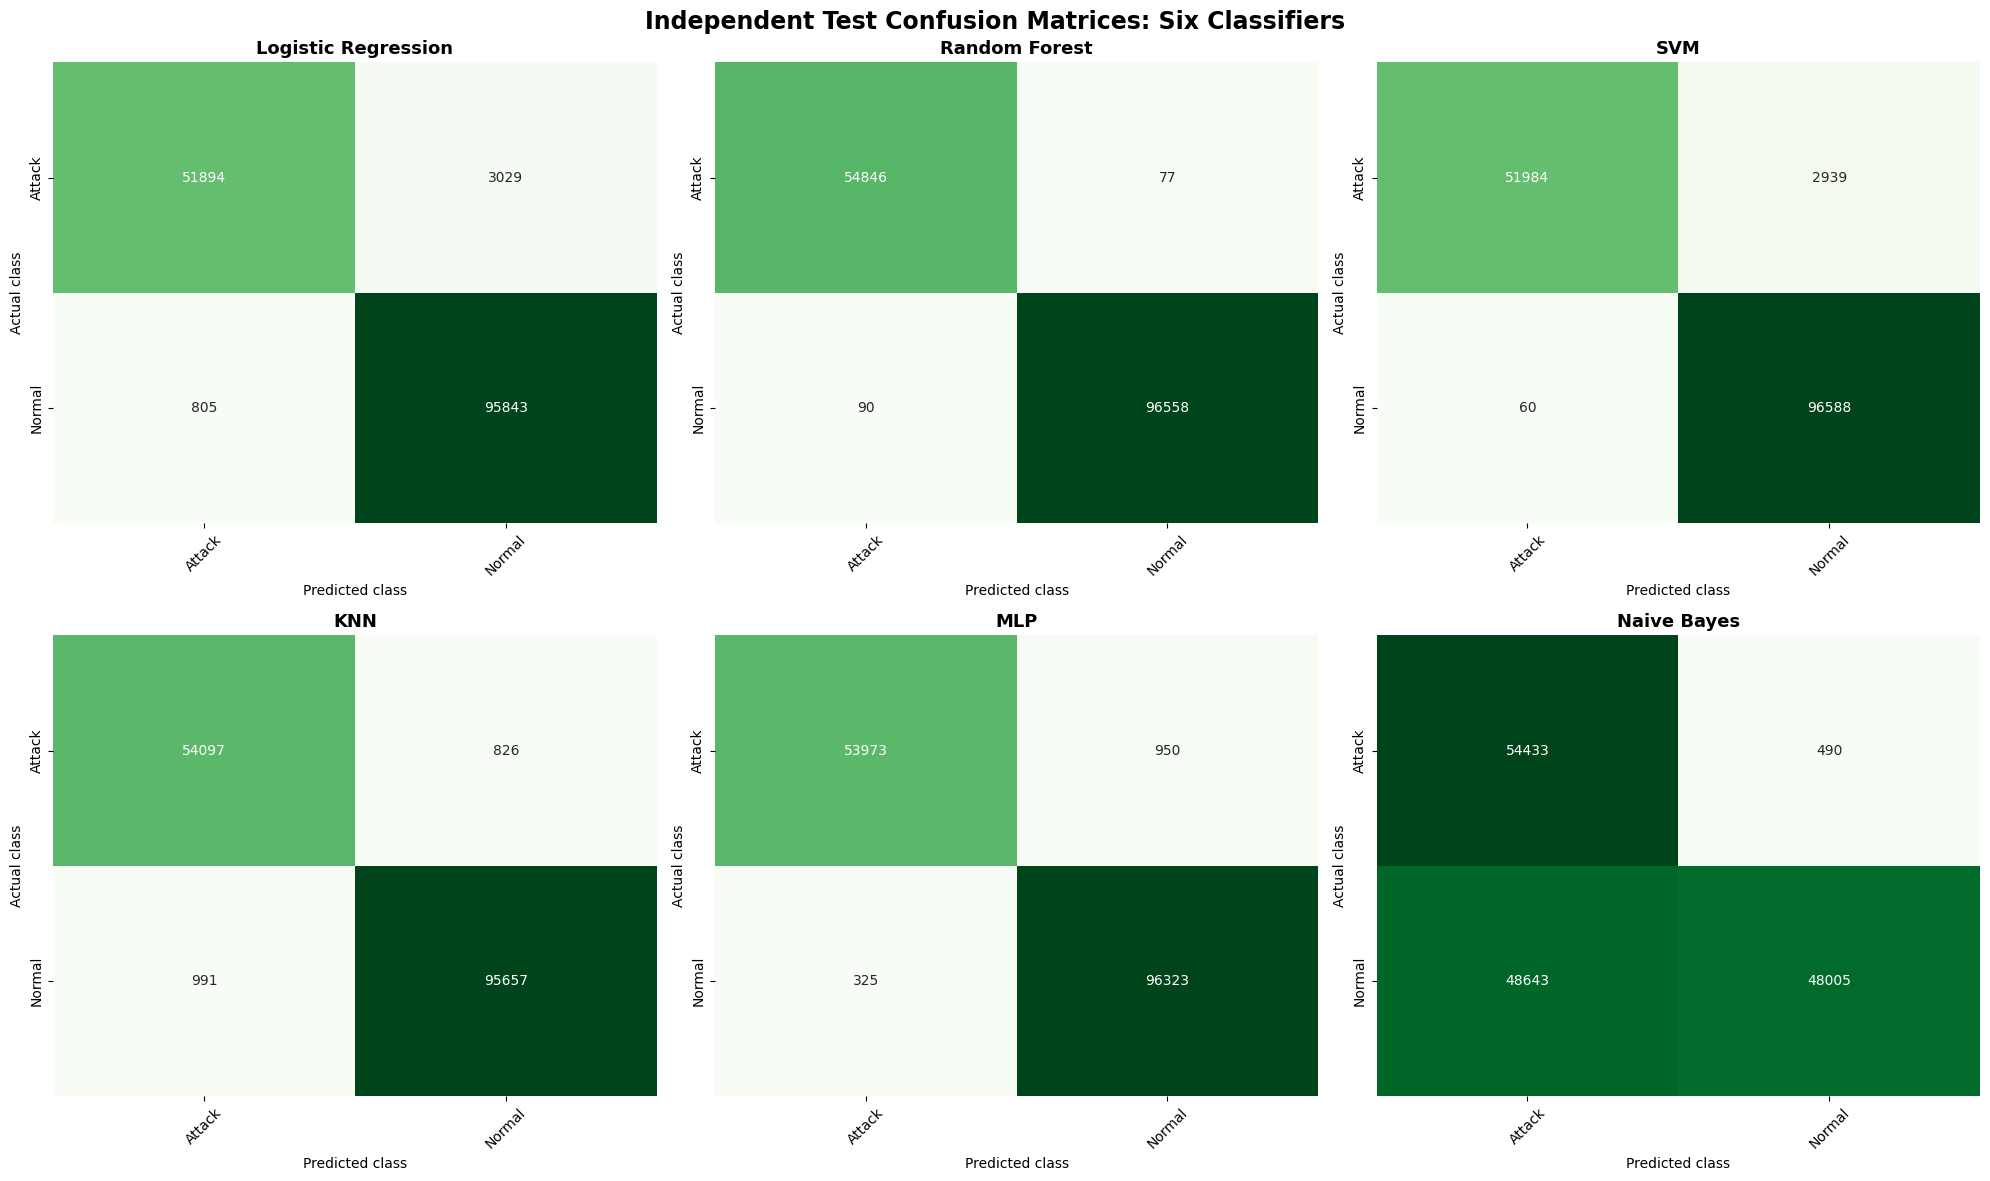

In [ ]:
# Six independent test confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

axes = axes.flatten()

for ax, name in zip(axes, classifiers):

    cm = confusion_matrix(
        ytest,
        test_predictions[name],
        labels=classes
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        cbar=False
    )

    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Independent Test Confusion Matrices: Six Classifiers",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

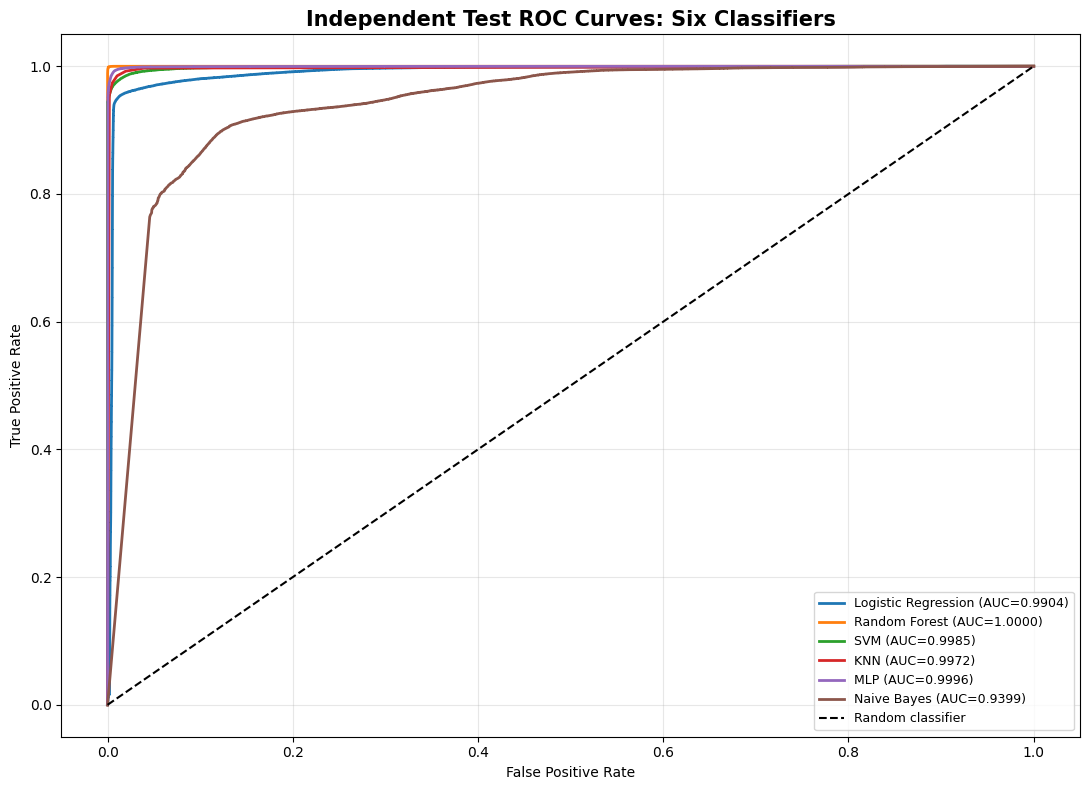

In [ ]:
# Independent test ROC Curves ---- Binary Classification
if len(classes) == 2:

    plt.figure(figsize=(11, 8))

    y_test_binary = (np.asarray(ytest) == positive_label).astype(int)

    pos_idx = np.where(classes == positive_label)[0][0]

    for name in classifiers:

        scores = test_probabilities[name][:, pos_idx]

        fpr, tpr, _ = roc_curve(y_test_binary, scores)

        test_auc = roc_auc_score(y_test_binary, scores)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{name} (AUC={test_auc:.4f})"
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="black",
        label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(
        "Independent Test ROC Curves: Six Classifiers",
        fontsize=15,
        fontweight="bold"
    )

    plt.legend(loc="lower right", fontsize=9)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

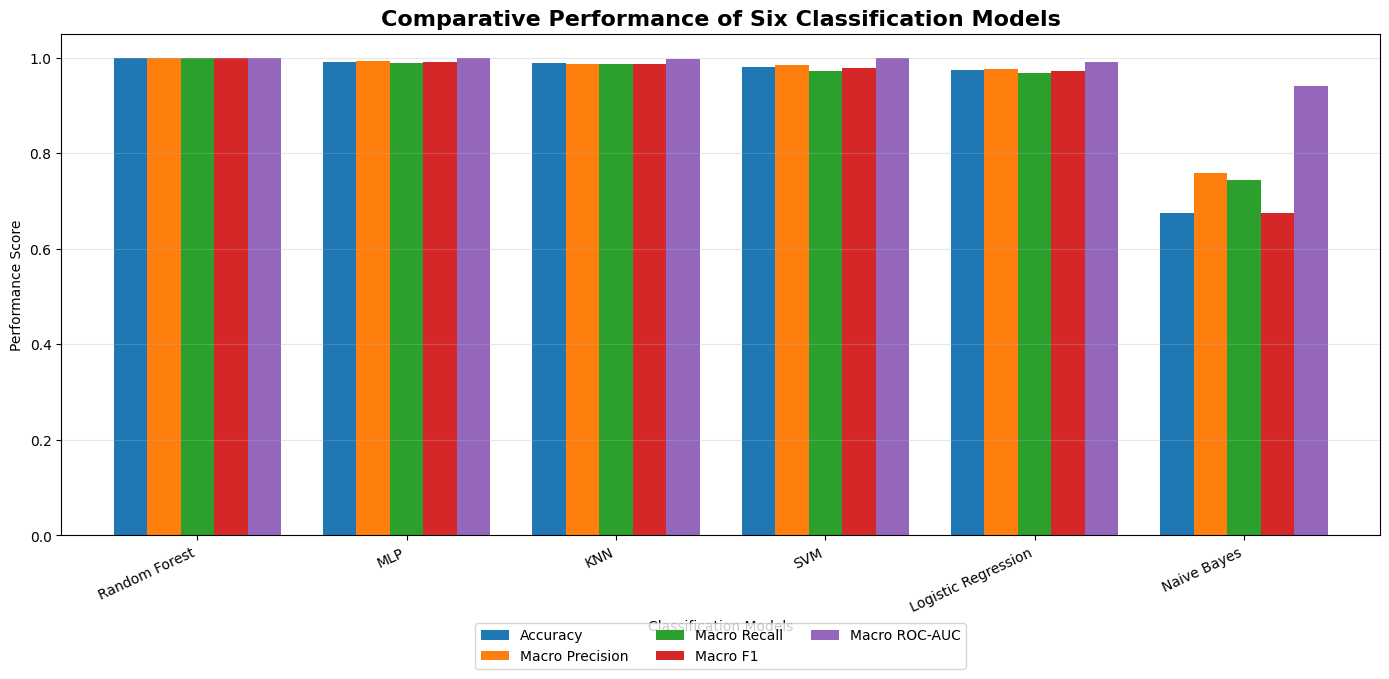

In [ ]:
# Visual Comparison of the six classifiers
metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Macro ROC-AUC"
]

plot_data = test_summary.set_index(
    "Classifier"
)[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

ax.set_title(
    "Comparative Performance of Six Classification Models",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel("Performance Score")
ax.set_xlabel("Classification Models")

ax.set_ylim(0, 1.05)
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=3
)

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()